# Treino sem as notas zero, com busca de hiperparâmetros

**Pergunta:** treinar **sem as pessoas que tiraram 0** melhora a previsão?

**A regra do PDF (Seção 4, "Notas zero"):** nota zero é um resultado observado e a equipe pode investigar sua influência. Se testar o treino sem zeros, deve compará-lo com o treino que os inclui, **com o mesmo modelo e os mesmos participantes, inclusive os zeros, na validação e no teste**. A exclusão experimental acontece **somente no treino de cada dobra**. Uma avaliação só entre as notas positivas descreve outra população e **não comprova melhoria**.

Por isso este notebook **não usa um dataset sem os zeros**: o conjunto de validação continua com todos. O que muda é o treino, dentro da validação cruzada: a classe `SemZerosNoTreino` (seção 0) tira os zeros só das 2 dobras de treino e o modelo prevê para todo mundo, inclusive para quem zerou.

| Seção | Conteúdo |
|---|---|
| 0 | Preparação, a classe `SemZerosNoTreino`, a busca e a comparação com e sem zeros |
| 1 | Regressão linear com e sem zeros (sem busca) |
| 2 | Ridge (busca) |
| 3 | Árvore de decisão (busca) |
| 4 | Gradient Boosting (busca) |
| 5 | Random Forest (busca, **desligada** por padrão: leva cerca de 1 hora) |
| 6 | Comparação final e efeito por faixa de nota |

**Otimizador:** `RandomizedSearchCV` com 10 configurações por modelo, nas mesmas 3 dobras, semente 42. A busca é feita **treinando sem zeros**; depois a **melhor configuração** é medida de dois jeitos (treino com zeros e treino sem zeros) para a comparação ser justa. Ficam de fora KNN, SVR, bagging, pasting e stacking por custo; o `BUSCAR` da seção 0 liga e desliga os modelos.

**Tempo estimado:** de 40 a 60 minutos com a Random Forest desligada.

Os zeros são 13.300 pessoas (0,62% do desenvolvimento), mas geram cerca de 14% do erro ao quadrado da regressão linear, porque o modelo prevê ~520 para quem tirou 0. O que este notebook mede é o quanto tirar essas pessoas do **treino** ajuda ou atrapalha.

## 0. Preparação

Igual aos outros notebooks: lê o dataset, fica **só com o desenvolvimento** (80%) e carrega as dobras salvas. Para outro dataset, troque a linha `NOME`.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import PredefinedSplit, cross_val_predict, cross_validate

DATASETS = ["dataset_1_fundido", "dataset_1_features", "dataset_2_escola", "dataset_2_features_escola",
            "dataset_3_sem_escola", "dataset_3_sem_escola_features", "dataset_3_escola", "dataset_3_escola_features"]
NOME = "dataset_1_fundido"        # para treinar em outro dataset, troque só esta linha

# quem está no desenvolvimento (80%) e a dobra (1, 2 ou 3) de cada pessoa: arquivos salvos em dados/splits/
ids = pd.read_csv("../dados/processed/ids_elegiveis.csv")["NU_INSCRICAO"]
em_desenvolvimento = ids.isin(pd.read_csv("../dados/splits/desenvolvimento_ids.csv")["NU_INSCRICAO"]).to_numpy()
dobras = PredefinedSplit(pd.read_csv("../dados/splits/dobras_cv.csv")["dobra"].to_numpy())


def carregar(nome):
    """Lê o dataset e devolve só o desenvolvimento: X (features) e y (nota de Matemática). O teste não é carregado."""
    dev = pd.read_csv(f"../dados/processed/{nome}.csv")[em_desenvolvimento]
    return dev.drop(columns="NU_NOTA_MT"), dev["NU_NOTA_MT"]


X, y = carregar(NOME)
amostra = np.random.default_rng(42).choice(len(y), 20_000, replace=False)   # 20 mil pessoas sorteadas, só para desenhar gráficos
resultados = {}                                                             # aqui ficam as métricas de cada modelo, para a comparação final
print(f"{NOME}: {X.shape[0]:,} pessoas no desenvolvimento, {X.shape[1]} features")

dataset_1_fundido: 2,153,941 pessoas no desenvolvimento, 30 features


A função `avaliar` mede um modelo: ele treina em 2 dobras, é testado na terceira, três vezes, e ela devolve a **média** e o **desvio** de cada métrica. Se você passar um nome, o resultado também vai para `resultados`.

- **RMSE:** o erro típico em pontos de nota (pune mais os erros grandes). É a métrica principal.
- **MAE:** o erro médio em pontos, sem sinal.
- **R²:** quanto da variação da nota o modelo explica (0 = nada além da média, 1 = tudo).
- **MSE:** o erro ao quadrado médio; o RMSE é a raiz dele.
- **tempo_s:** segundos para treinar e prever em uma dobra.

In [2]:
def avaliar(modelo, nome=None):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}      # o scikit-learn devolve os erros com sinal negativo
    r = cross_validate(modelo, X, y, cv=dobras, scoring=metricas)
    por_dobra = pd.DataFrame({"RMSE": -r["test_RMSE"], "MAE": -r["test_MAE"], "R2": r["test_R2"], "MSE": -r["test_MSE"],
                              "tempo_s": r["fit_time"] + r["score_time"]})
    resumo = pd.DataFrame({"média": por_dobra.mean(), "desvio": por_dobra.std()})
    if nome:
        resultados[nome] = resumo
    return resumo.round(3)

Três funções de apoio para os modelos que demoram. Elas treinam **na dobra 1** (não repetem a validação cruzada inteira):

- `real_x_previsto`: desenha 20 mil pessoas da validação, nota real contra nota prevista.
- `importancia_por_permutacao`: embaralha uma coluna da validação e mede **quanto o RMSE sobe**; quanto mais sobe, mais o modelo dependia daquela feature. Serve para qualquer modelo.
- `grafico_importancia`: desenha as 15 maiores.

In [3]:
from sklearn.inspection import permutation_importance


def treinar_dobra1(modelo):
    treino, validacao = next(iter(dobras.split()))
    return clone(modelo).fit(X.iloc[treino], y.iloc[treino]), validacao


def real_x_previsto(modelo, titulo):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(20_000, len(validacao)), replace=False)
    plt.figure(figsize=(6, 5))
    plt.scatter(y.iloc[sorteio], m.predict(X.iloc[sorteio]), s=3, alpha=0.1)
    plt.plot([0, 1000], [0, 1000], color="green", label="previsão perfeita")
    plt.title(f"Nota real x nota prevista ({titulo})")
    plt.xlabel("nota real")
    plt.ylabel("nota prevista")
    plt.legend()
    plt.show()


def importancia_por_permutacao(modelo, n_linhas=5000, repeticoes=3):
    m, validacao = treinar_dobra1(modelo)
    sorteio = np.random.default_rng(42).choice(validacao, min(n_linhas, len(validacao)), replace=False)
    r = permutation_importance(m, X.iloc[sorteio], y.iloc[sorteio], scoring="neg_root_mean_squared_error",
                               n_repeats=repeticoes, random_state=42)
    return pd.Series(r.importances_mean, index=X.columns).sort_values()


def grafico_importancia(serie, titulo, xlabel):
    top = serie.tail(15)
    plt.figure(figsize=(7, 5))
    plt.barh(top.index, top.values)
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.show()

**A classe `SemZerosNoTreino`.** Ela embrulha qualquer modelo. Com `tirar_zeros=True`, na hora de **treinar** ela descarta as pessoas com nota 0; na hora de **prever**, prevê para todo mundo. Dentro da validação cruzada isso acontece só nas 2 dobras de treino: a dobra de validação continua inteira, com os zeros. Com `tirar_zeros=False` ela não descarta ninguém (é o treino "com zeros", usado na comparação).

In [4]:
from sklearn.base import BaseEstimator, RegressorMixin


class SemZerosNoTreino(RegressorMixin, BaseEstimator):
    def __init__(self, estimador, tirar_zeros=True):
        self.estimador = estimador
        self.tirar_zeros = tirar_zeros

    def fit(self, X, y):
        y = np.asarray(y)
        manter = (y > 0) if self.tirar_zeros else np.ones(len(y), dtype=bool)      # só no treino
        self.estimador_ = clone(self.estimador).fit(X.iloc[manter], y[manter])
        return self

    def predict(self, X):
        return self.estimador_.predict(X)                                         # prevê para todo mundo, inclusive quem zerou


zeros_no_treino = int((y == 0).sum())
print(f"{zeros_no_treino:,} pessoas com nota 0 no desenvolvimento ({zeros_no_treino / len(y) * 100:.2f}%); "
      "elas saem do treino de cada dobra, mas continuam na validação.")

13,300 pessoas com nota 0 no desenvolvimento (0.62%); elas saem do treino de cada dobra, mas continuam na validação.


A função `buscar` é a mesma do notebook otimizado: sorteia `N_ITER` configurações, mede cada uma nas 3 dobras, escolhe a de menor RMSE e reajusta nos 80%. Aqui os nomes dos hiperparâmetros ganham o prefixo `estimador__` (porque o modelo está dentro do `SemZerosNoTreino`).

In [5]:
import time
from pathlib import Path

from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV

N_ITER = 10                       # configurações sorteadas por modelo (o PDF pede no mínimo 10)
BUSCAR = {"Ridge": True, "Árvore de decisão": True, "SVR linear": True, "Bagging": True,
          "Pasting": True, "Random Forest": True, "Gradient Boosting": True}      # False pula a busca daquele modelo
melhores = {}                     # melhor modelo de cada busca, já reajustado nos 80%
parametros = {}                   # os melhores hiperparâmetros de cada busca
Path("../resultados/tabelas").mkdir(parents=True, exist_ok=True)


def buscar(modelo, espaco, nome):
    metricas = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error",
                "R2": "r2", "MSE": "neg_mean_squared_error"}
    busca = RandomizedSearchCV(modelo, espaco, n_iter=N_ITER, cv=dobras, scoring=metricas, refit="RMSE",
                               random_state=42, n_jobs=1)
    t0 = time.time()
    busca.fit(X, y)                                                        # testa as N_ITER configurações e reajusta a melhor nos 80%
    minutos = (time.time() - t0) / 60

    r = pd.DataFrame(busca.cv_results_)
    melhor = busca.best_index_
    media, desvio = {}, {}
    for m, sinal in {"RMSE": -1, "MAE": -1, "R2": 1, "MSE": -1}.items():
        media[m], desvio[m] = sinal * r.loc[melhor, f"mean_test_{m}"], r.loc[melhor, f"std_test_{m}"]
    media["tempo_s"] = r.loc[melhor, "mean_fit_time"] + r.loc[melhor, "mean_score_time"]
    desvio["tempo_s"] = r.loc[melhor, "std_fit_time"]
    resultados[nome] = pd.DataFrame({"média": media, "desvio": desvio})
    melhores[nome], parametros[nome] = busca.best_estimator_, busca.best_params_

    tabela = pd.DataFrame({"parametros": [str(p) for p in r["params"]], "RMSE": -r["mean_test_RMSE"],
                           "RMSE_desvio": r["std_test_RMSE"], "MAE": -r["mean_test_MAE"], "R2": r["mean_test_R2"],
                           "tempo_s": r["mean_fit_time"] + r["mean_score_time"]}).sort_values("RMSE")
    tabela.to_csv(f"../resultados/tabelas/busca_sem_zeros_{nome.lower().replace(' ', '_')}.csv", index=False)
    print(f"{nome}: {N_ITER} configurações em {minutos:.1f} min")
    print("Melhores hiperparâmetros:", busca.best_params_)
    print(f"RMSE nas 3 dobras: {media['RMSE']:.3f} ± {desvio['RMSE']:.3f}   (R² {media['R2']:.3f})")
    return tabela.head(5).round(3)

**A função `comparar`.** Pega o modelo já com os melhores hiperparâmetros e faz a **mesma validação cruzada duas vezes**, uma treinando com zeros e outra sem. Em ambas a validação tem todos os participantes. Mostra o RMSE, MAE e R² médios (± desvio entre as dobras) e o **efeito por faixa de nota**: erro típico (RMSE) e **viés** (média de nota real − prevista; positivo = o modelo prevê menos que a nota real). Guarda tudo em `comparativo`.

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

comparativo = {}
FAIXAS = [-1, 0, 400, 500, 600, 700, 800, 1000]          # a menor nota positiva é ~320, então não há faixa abaixo de 400 além do zero
ROTULOS = ["0", "1-400", "400-500", "500-600", "600-700", "700-800", "800+"]


def metricas_por_dobra(previsto):
    linhas = []
    for treino, validacao in dobras.split():
        real, prev = y.iloc[validacao], previsto[validacao]
        linhas.append({"RMSE": root_mean_squared_error(real, prev), "MAE": mean_absolute_error(real, prev), "R2": r2_score(real, prev)})
    t = pd.DataFrame(linhas)
    return pd.DataFrame({"média": t.mean(), "desvio": t.std()})


def comparar(nome, modelo_sem_zeros):
    """modelo_sem_zeros: SemZerosNoTreino com os melhores hiperparâmetros."""
    com = clone(modelo_sem_zeros).set_params(tirar_zeros=False)
    sem = clone(modelo_sem_zeros).set_params(tirar_zeros=True)
    prev_com = cross_val_predict(com, X, y, cv=dobras)                 # previsão de cada pessoa, feita sem ela no treino
    prev_sem = cross_val_predict(sem, X, y, cv=dobras)
    geral = {"treino COM zeros": metricas_por_dobra(prev_com), "treino SEM zeros": metricas_por_dobra(prev_sem)}

    faixa = pd.cut(y, bins=FAIXAS, labels=ROTULOS)
    linhas = []
    for f in ROTULOS:
        m = (faixa == f).to_numpy()
        if m.sum() == 0:
            continue                                                       # faixa vazia
        linhas.append({"faixa": f, "pessoas": int(m.sum()),
                       "RMSE com zeros": root_mean_squared_error(y[m], prev_com[m]), "RMSE sem zeros": root_mean_squared_error(y[m], prev_sem[m]),
                       "viés com zeros": (y[m] - prev_com[m]).mean(), "viés sem zeros": (y[m] - prev_sem[m]).mean()})
    por_faixa = pd.DataFrame(linhas).set_index("faixa")
    comparativo[nome] = {"geral": geral, "por_faixa": por_faixa}

    tabela = pd.DataFrame({k: v["média"] for k, v in geral.items()}).T
    tabela["RMSE_desvio"] = [v.loc["RMSE", "desvio"] for v in geral.values()]
    print(f"{nome}: o que muda ao tirar os zeros do treino (validação com TODOS os participantes)")
    print(tabela.round(3).to_string())
    dif = geral["treino COM zeros"].loc["RMSE", "média"] - geral["treino SEM zeros"].loc["RMSE", "média"]
    print(f"\nDiferença de RMSE (com − sem): {dif:+.3f}  (desvio entre dobras: {geral['treino COM zeros'].loc['RMSE', 'desvio']:.3f})")
    return por_faixa.round(2)

## 1. Regressão linear com e sem zeros

Sem busca (a regressão linear não tem hiperparâmetros). É o caso mais simples para enxergar o efeito: o mesmo modelo, treinado de duas formas, validado nos mesmos participantes.

In [7]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

regressao_linear = SemZerosNoTreino(make_pipeline(StandardScaler(), LinearRegression()))
comparar("Regressão linear", regressao_linear)

Regressão linear: o que muda ao tirar os zeros do treino (validação com TODOS os participantes)
                     RMSE     MAE     R2  RMSE_desvio
treino COM zeros  111.153  86.960  0.287        0.178
treino SEM zeros  111.202  87.053  0.286        0.187

Diferença de RMSE (com − sem): -0.049  (desvio entre dobras: 0.178)


,pessoas,RMSE com zeros,RMSE sem zeros,viés com zeros,viés sem zeros
faixa,,,,,
0,13300,522.64,526.04,-518.64,-522.09
1-400,335333,131.09,134.13,-119.68,-123.11
400-500,596764,81.10,83.26,-55.72,-59.07
500-600,527327,64.87,63.79,18.07,14.84
600-700,433346,103.77,101.23,80.85,77.78
700-800,202528,147.40,144.73,131.67,128.78
800+,45343,210.37,207.73,199.60,196.89


**Como ler a tabela por faixa:** o viés da faixa "0" é a nota real menos a prevista para quem zerou (muito negativo = o modelo prevê alto demais). Ao tirar os zeros do treino, o modelo deixa de "puxar" as previsões para baixo, então espere o viés dos zeros **piorar** (prever ainda mais alto) e o das notas altas melhorar. A pergunta é se o saldo no RMSE geral compensa.

In [8]:
comparativo["Regressão linear"]["por_faixa"].round(2)

,pessoas,RMSE com zeros,RMSE sem zeros,viés com zeros,viés sem zeros
faixa,,,,,
0,13300,522.64,526.04,-518.64,-522.09
1-400,335333,131.09,134.13,-119.68,-123.11
400-500,596764,81.10,83.26,-55.72,-59.07
500-600,527327,64.87,63.79,18.07,14.84
600-700,433346,103.77,101.23,80.85,77.78
700-800,202528,147.40,144.73,131.67,128.78
800+,45343,210.37,207.73,199.60,196.89


Salvar o modelo treinado sem zeros nos 80% do desenvolvimento:

In [9]:
joblib.dump(clone(regressao_linear).fit(X, y), f"../models/regressao_linear_sem_zeros_{NOME}.joblib")

['../models/regressao_linear_sem_zeros_dataset_1_fundido.joblib']

**Quais modelos buscar.** `BUSCAR` liga e desliga cada um. A Random Forest vem desligada por ser a mais lenta (cerca de 1 hora de busca).

In [10]:
BUSCAR = {"Ridge": True, "Árvore de decisão": True, "Gradient Boosting": True, "Random Forest": False}      # False pula o modelo
espaco_prefixo = lambda espaco: {f"estimador__{k}": v for k, v in espaco.items()}

## 2. Ridge

A busca sorteia o `alpha` (força do freio) de 0,001 a 100.000, em escala logarítmica, **treinando sem zeros**. Estimativa: menos de 1 minuto.

In [11]:
if BUSCAR["Ridge"]:
    ridge = SemZerosNoTreino(make_pipeline(StandardScaler(), Ridge()))
    top = buscar(ridge, espaco_prefixo({"ridge__alpha": loguniform(1e-3, 1e5)}), "Ridge")
else:
    top = None
top

Ridge: 10 configurações em 1.4 min
Melhores hiperparâmetros: {'estimador__ridge__alpha': np.float64(0.0029152036385288304)}
RMSE nas 3 dobras: 111.202 ± 0.153   (R² 0.286)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
6,{'estimador__ridge__alpha': np.float64(0.00291...,111.202,0.153,87.053,0.286,2.421
5,{'estimador__ridge__alpha': np.float64(0.01769...,111.202,0.153,87.053,0.286,0.925
4,{'estimador__ridge__alpha': np.float64(0.01770...,111.202,0.153,87.053,0.286,1.025
0,{'estimador__ridge__alpha': np.float64(0.99156...,111.202,0.153,87.053,0.286,4.801
3,{'estimador__ridge__alpha': np.float64(61.5556...,111.202,0.153,87.053,0.286,2.919


### Comparação: treino com zeros × sem zeros

Mesmos hiperparâmetros (os melhores da busca), mesmas 3 dobras, validação com todos.

In [12]:
if "Ridge" in melhores:
    tabela_faixa = comparar("Ridge", melhores["Ridge"])
    print()
    print(tabela_faixa.to_string())
    joblib.dump(melhores["Ridge"], f"../models/ridge_sem_zeros_{NOME}.joblib")

Ridge: o que muda ao tirar os zeros do treino (validação com TODOS os participantes)
                     RMSE     MAE     R2  RMSE_desvio
treino COM zeros  111.153  86.960  0.287        0.178
treino SEM zeros  111.202  87.053  0.286        0.187

Diferença de RMSE (com − sem): -0.049  (desvio entre dobras: 0.178)

         pessoas  RMSE com zeros  RMSE sem zeros  viés com zeros  viés sem zeros
faixa                                                                           
0          13300          522.64          526.04         -518.64         -522.09
1-400     335333          131.09          134.13         -119.68         -123.11
400-500   596764           81.10           83.26          -55.72          -59.07
500-600   527327           64.87           63.79           18.07           14.84
600-700   433346          103.77          101.23           80.85           77.78
700-800   202528          147.40          144.73          131.67          128.78
800+       45343          210.37   

## 3. Árvore de decisão

Faixas: `max_depth` de 5 a 30, `min_samples_leaf` de 5 a 299 e `max_features` (`None`, 0,8 ou 0,5). Estimativa: cerca de 5 minutos.

In [13]:
from sklearn.tree import DecisionTreeRegressor

if BUSCAR["Árvore de decisão"]:
    arvore = SemZerosNoTreino(DecisionTreeRegressor(random_state=42))
    espaco = {"max_depth": randint(5, 31), "min_samples_leaf": randint(5, 300), "max_features": [None, 0.8, 0.5]}
    top = buscar(arvore, espaco_prefixo(espaco), "Árvore de decisão")
else:
    top = None
top

Árvore de decisão: 10 configurações em 7.2 min
Melhores hiperparâmetros: {'estimador__max_depth': 25, 'estimador__max_features': 0.8, 'estimador__min_samples_leaf': 298}
RMSE nas 3 dobras: 110.331 ± 0.172   (R² 0.297)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
5,"{'estimador__max_depth': 25, 'estimador__max_f...",110.331,0.172,86.165,0.297,15.962
9,"{'estimador__max_depth': 14, 'estimador__max_f...",110.394,0.167,86.231,0.297,12.721
4,"{'estimador__max_depth': 25, 'estimador__max_f...",110.403,0.150,86.182,0.297,10.784
0,"{'estimador__max_depth': 11, 'estimador__max_f...",110.418,0.169,86.293,0.296,11.069
3,"{'estimador__max_depth': 15, 'estimador__max_f...",110.458,0.169,86.229,0.296,10.353


### Comparação: treino com zeros × sem zeros

Mesmos hiperparâmetros (os melhores da busca), mesmas 3 dobras, validação com todos.

In [14]:
if "Árvore de decisão" in melhores:
    tabela_faixa = comparar("Árvore de decisão", melhores["Árvore de decisão"])
    print()
    print(tabela_faixa.to_string())
    joblib.dump(melhores["Árvore de decisão"], f"../models/arvore_decisao_sem_zeros_{NOME}.joblib")

Árvore de decisão: o que muda ao tirar os zeros do treino (validação com TODOS os participantes)
                     RMSE     MAE     R2  RMSE_desvio
treino COM zeros  110.337  86.113  0.297        0.181
treino SEM zeros  110.331  86.165  0.297        0.210

Diferença de RMSE (com − sem): +0.006  (desvio entre dobras: 0.181)

         pessoas  RMSE com zeros  RMSE sem zeros  viés com zeros  viés sem zeros
faixa                                                                           
0          13300          519.97          523.39         -515.92         -519.42
1-400     335333          129.51          132.52         -117.83         -121.29
400-500   596764           80.83           82.85          -54.32          -57.68
500-600   527327           66.70           65.49           18.69           15.43
600-700   433346          104.32          101.67           79.83           76.75
700-800   202528          144.34          141.73          127.24          124.63
800+       45343       

## 4. Gradient Boosting

Faixas: `learning_rate` de 0,02 a 0,3 (escala log), `max_iter` 200, 300 ou 500, `max_leaf_nodes` de 15 a 99, `min_samples_leaf` de 50 a 499 e `l2_regularization` de 0,001 a 10 (escala log). Estimativa: de 15 a 25 minutos.

In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor

if BUSCAR["Gradient Boosting"]:
    gradient_boosting = SemZerosNoTreino(HistGradientBoostingRegressor(early_stopping=True, validation_fraction=0.1, n_iter_no_change=10, random_state=42))
    espaco = {"learning_rate": loguniform(0.02, 0.3), "max_iter": [200, 300, 500], "max_leaf_nodes": randint(15, 100),
              "min_samples_leaf": randint(50, 500), "l2_regularization": loguniform(1e-3, 10)}
    top = buscar(gradient_boosting, espaco_prefixo(espaco), "Gradient Boosting")
else:
    top = None
top

Gradient Boosting: 10 configurações em 75.4 min
Melhores hiperparâmetros: {'estimador__l2_regularization': np.float64(0.24400607090817547), 'estimador__learning_rate': np.float64(0.06689135590392836), 'estimador__max_iter': 500, 'estimador__max_leaf_nodes': 89, 'estimador__min_samples_leaf': 137}
RMSE nas 3 dobras: 107.737 ± 0.166   (R² 0.330)


,parametros,RMSE,RMSE_desvio,MAE,R2,tempo_s
1,{'estimador__l2_regularization': np.float64(0....,107.737,0.166,83.811,0.330,428.113
6,{'estimador__l2_regularization': np.float64(0....,107.745,0.186,83.823,0.330,175.537
9,{'estimador__l2_regularization': np.float64(7....,107.777,0.156,83.830,0.330,62.997
5,{'estimador__l2_regularization': np.float64(0....,107.781,0.171,83.872,0.330,200.762
4,{'estimador__l2_regularization': np.float64(9....,107.788,0.174,83.875,0.329,74.285


### Comparação: treino com zeros × sem zeros

Mesmos hiperparâmetros (os melhores da busca), mesmas 3 dobras, validação com todos.

In [16]:
if "Gradient Boosting" in melhores:
    tabela_faixa = comparar("Gradient Boosting", melhores["Gradient Boosting"])
    print()
    print(tabela_faixa.to_string())
    joblib.dump(melhores["Gradient Boosting"], f"../models/gradient_boosting_sem_zeros_{NOME}.joblib")

Gradient Boosting: o que muda ao tirar os zeros do treino (validação com TODOS os participantes)
                     RMSE     MAE     R2  RMSE_desvio
treino COM zeros  107.680  83.714  0.331        0.218
treino SEM zeros  107.737  83.811  0.330        0.204

Diferença de RMSE (com − sem): -0.057  (desvio entre dobras: 0.218)

         pessoas  RMSE com zeros  RMSE sem zeros  viés com zeros  viés sem zeros
faixa                                                                           
0          13300          516.17          520.09         -511.76         -515.77
1-400     335333          125.17          128.24         -112.73         -116.32
400-500   596764           79.32           81.32          -51.96          -55.37
500-600   527327           66.40           65.19           18.37           15.16
600-700   433346          102.15           99.65           77.04           74.12
700-800   202528          139.25          136.74          121.15          118.56
800+       45343       

## 5. Random Forest (desligada por padrão)

Faixas: `n_estimators` 50 ou 100, `max_depth` de 8 a 15, `min_samples_leaf` de 10 a 199, `max_features` 0,3, 0,5 ou 0,7. **Para ligar, troque `"Random Forest": False` por `True` na célula `BUSCAR` acima. Estimativa: de 40 a 60 minutos.**

In [17]:
from sklearn.ensemble import RandomForestRegressor

if BUSCAR["Random Forest"]:
    floresta = SemZerosNoTreino(RandomForestRegressor(n_jobs=-1, random_state=42))
    espaco = {"n_estimators": [50, 100], "max_depth": randint(8, 16), "min_samples_leaf": randint(10, 200), "max_features": [0.3, 0.5, 0.7]}
    top = buscar(floresta, espaco_prefixo(espaco), "Random Forest")
else:
    top = None
top

### Comparação: treino com zeros × sem zeros

Mesmos hiperparâmetros (os melhores da busca), mesmas 3 dobras, validação com todos.

In [18]:
if "Random Forest" in melhores:
    tabela_faixa = comparar("Random Forest", melhores["Random Forest"])
    print()
    print(tabela_faixa.to_string())
    joblib.dump(melhores["Random Forest"], f"../models/random_forest_sem_zeros_{NOME}.joblib")

## 6. Comparação final e efeito por faixa de nota

**Tabela geral:** RMSE de cada modelo treinando com e sem zeros, com a validação inteira (todos os participantes). Uma diferença menor que o desvio entre as dobras **não prova melhora**. Se tirar os zeros só ajudar numa faixa e piorar em outra, o PDF pede que isso seja relatado.

In [19]:
linhas = []
for nome, r in comparativo.items():
    com, sem = r["geral"]["treino COM zeros"], r["geral"]["treino SEM zeros"]
    linhas.append({"modelo": nome, "RMSE com zeros": com.loc["RMSE", "média"], "RMSE sem zeros": sem.loc["RMSE", "média"],
                   "diferença (com − sem)": com.loc["RMSE", "média"] - sem.loc["RMSE", "média"], "desvio entre dobras": com.loc["RMSE", "desvio"],
                   "R2 com zeros": com.loc["R2", "média"], "R2 sem zeros": sem.loc["R2", "média"],
                   "MAE com zeros": com.loc["MAE", "média"], "MAE sem zeros": sem.loc["MAE", "média"]})
final = pd.DataFrame(linhas).set_index("modelo")
final["veredito"] = np.where(final["diferença (com − sem)"] > final["desvio entre dobras"], "tirar zeros ajuda",
                             np.where(final["diferença (com − sem)"] < -final["desvio entre dobras"], "tirar zeros piora", "sem diferença clara"))
final.round(3)

,RMSE com zeros,RMSE sem zeros,diferença (com − sem),desvio entre dobras,R2 com zeros,R2 sem zeros,MAE com zeros,MAE sem zeros,veredito
modelo,,,,,,,,,
Regressão linear,111.153,111.202,-0.049,0.178,0.287,0.286,86.960,87.053,sem diferença clara
Ridge,111.153,111.202,-0.049,0.178,0.287,0.286,86.960,87.053,sem diferença clara
Árvore de decisão,110.337,110.331,0.006,0.181,0.297,0.297,86.113,86.165,sem diferença clara
Gradient Boosting,107.680,107.737,-0.057,0.218,0.331,0.330,83.714,83.811,sem diferença clara


**Gráfico geral.** O RMSE de cada modelo nos dois treinos. Barras do mesmo tamanho = sem efeito.

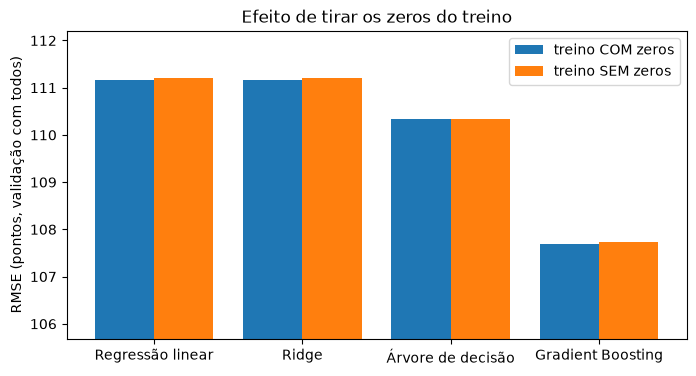

In [20]:
posicao = np.arange(len(final))
plt.figure(figsize=(8, 4))
plt.bar(posicao - 0.2, final["RMSE com zeros"], width=0.4, label="treino COM zeros")
plt.bar(posicao + 0.2, final["RMSE sem zeros"], width=0.4, label="treino SEM zeros")
plt.xticks(posicao, final.index)
plt.ylim(final[["RMSE com zeros", "RMSE sem zeros"]].min().min() - 2, final[["RMSE com zeros", "RMSE sem zeros"]].max().max() + 1)
plt.ylabel("RMSE (pontos, validação com todos)")
plt.title("Efeito de tirar os zeros do treino")
plt.legend()
plt.show()

**Efeito por faixa de nota** para o melhor modelo (o de menor RMSE sem zeros). À esquerda, o erro típico por faixa; à direita, o viés. Espere os zeros e as notas baixas piorarem e as notas altas melhorarem, ou o contrário, é o que o PDF pede para relatar.

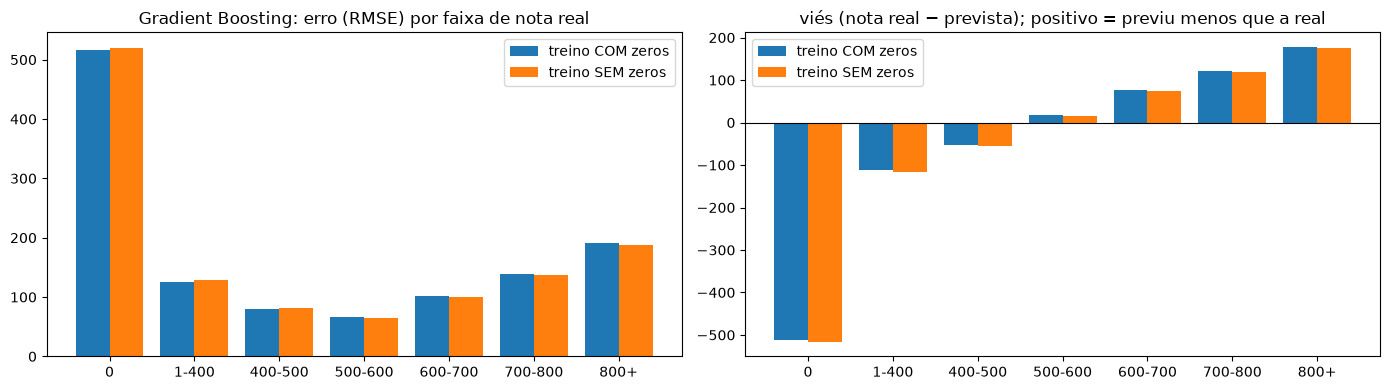

Faixa '0': só 0,62% das pessoas, mas o erro dela é grande. Faixas de nota alta: poucas pessoas, mas são as que o modelo mais subestima.


In [21]:
melhor = final["RMSE sem zeros"].idxmin()
faixa = comparativo[melhor]["por_faixa"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(faixa))
ax[0].bar(x - 0.2, faixa["RMSE com zeros"], width=0.4, label="treino COM zeros")
ax[0].bar(x + 0.2, faixa["RMSE sem zeros"], width=0.4, label="treino SEM zeros")
ax[0].set_xticks(x, faixa.index)
ax[0].set_title(f"{melhor}: erro (RMSE) por faixa de nota real")
ax[0].legend()
ax[1].bar(x - 0.2, faixa["viés com zeros"], width=0.4, label="treino COM zeros")
ax[1].bar(x + 0.2, faixa["viés sem zeros"], width=0.4, label="treino SEM zeros")
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set_xticks(x, faixa.index)
ax[1].set_title("viés (nota real − prevista); positivo = previu menos que a real")
ax[1].legend()
plt.tight_layout()
plt.show()
print("Faixa '0': só 0,62% das pessoas, mas o erro dela é grande. Faixas de nota alta: poucas pessoas, mas são as que o modelo mais subestima.")

**O que registrar (PDF):** a justificativa do experimento (os zeros geram ~14% do erro ao quadrado e o modelo os prevê em ~520), o efeito geral (tabela) e o efeito por faixa (gráfico). Lembrete: o RMSE medido **só entre quem não zerou** é menor, mas descreve outra população e **não comprova melhoria**; ele aparece aqui apenas como descrição do tamanho do problema.